# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neilivanorencia/flyrank-ml-internship/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

The baseline notebook froze a readable rule (rule B: missed clicks against the position-bin expectation, counted when the page fell short by the target's own rule) as the bar to beat. This notebook trains four learned models on the same rows, the same target, and the same metrics, tests them on months and clients they never saw, and compares them with rule B in one table computed in this run. It then reads what the models lean on and where they go wrong, because a score is only worth believing once its errors make sense.

**How to read it:** each section opens with the thinking, then a **Method** note explaining what the next code cell computes, then the output, then a **Finding** note on what it shows. Terms from the earlier notebooks (month M, month M+1, expected clicks, the target, Precision@K, Capture@50, size bands, rule B) still apply; the new ones are defined below.


## Key terms

| Term                         | Technical meaning                                                                                   | In plain words                                                                            |
| ---------------------------- | --------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------- |
| **Learned parameter**        | A value the training algorithm fits from the data, such as a weight or a split point                | What the model discovers on its own                                                       |
| **Setting (hyperparameter)** | A value fixed before training that controls how the model learns, such as tree depth                | A dial set by hand, before any result is seen                                             |
| **Logistic regression**      | A weighted sum of the features passed through an S-shaped curve to give a probability               | One weight per feature; the most readable model                                           |
| **Decision tree**            | A sequence of yes/no splits on single features, ending in leaves with a share of positives          | A short list of if-then rules                                                             |
| **Random forest**            | Many decision trees, each grown on a random sample of rows, averaged                                | A committee of trees that smooths out each tree's quirks                                  |
| **Gradient boosting**        | Trees added one at a time, each fitted to the errors of the trees before it                         | Each new tree corrects the mistakes of the previous ones                                  |
| **Early stopping**           | Stopping the boosting once a held-out set stops improving                                           | Adding trees only while they still help on unseen data                                    |
| **Walk-forward split**       | Training on earlier month pairs and testing on a later one                                          | Testing the way the queue is used: built from the past, judged on the future              |
| **Client fold**              | A group of clients held out together; a model never trains on the clients it is tested on           | Testing only on sites the model has never seen                                            |
| **Out-of-fold score**        | A score for each test page from a model that never saw its client                                   | Every test score comes from an unseen client                                              |
| **Average precision**        | The area under the precision-recall curve; its random level equals the base rate                    | A whole-ranking score that is not flattered by a rare target                              |
| **Permutation importance**   | The drop in a score when one feature's values are shuffled across pages                             | How much the model loses when it can no longer use that feature                           |
| **SHAP value**               | One page's score split into a contribution from each feature (Shapley values)                       | Which features pushed this page's score up or down, and by how much                       |
| **Inner folds**              | Client-grouped folds inside the training data only                                                  | A rehearsal on training clients, used to choose a setting without touching the test pages |
| **Per-fold Precision@10**    | Precision@10 inside each client fold, ranked by that fold's own model, averaged over the five folds | The same 50 picks, but each fold model judged on its own scale                            |
| **Tie-aware Precision@K**    | Precision@K where pages tied at the cut-off count by the share of positives among them              | A fair Precision@50 for a model that gives many pages the same score                      |


**Method:** this cell makes sure DuckDB is version 1.1 or newer (its Hugging Face login reads the token from the environment) and installs `shap`, which explains the models' scores page by page.


In [1]:
%pip -q install "duckdb>=1.1" shap

## Setup

**Method, step by step:**

1. **Finds the project folder** and **reads the Hugging Face token**, as in the data contract: environment variable or `.env` file, then a Colab Secret named `HF_TOKEN`, then a typed prompt as the last resort. DuckDB reads the token from the environment, so it never appears in a query or an output.
2. **Loads the tools.** `duckdb` queries the warehouse, `pandas` and `numpy` handle the results, `scipy` supplies the negative binomial luck test behind the target and rule B, `scikit-learn` supplies the four models, the fold splitters, and the metrics, `shap` explains individual scores, and `matplotlib` draws the one chart.
3. **Defines the months and the cache.** The same three development pairs as the data contract; June 2026 is never read. Heavy queries go through `cached()`, which saves each result once under `work/outputs/w03_cache/` and reuses it on later runs.
4. **Defines `show()` and `show_table()`**, which display every result as a titled table.


In [2]:
import getpass
import os
import sys
import tempfile
import time
import urllib.request

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import Markdown, display
from matplotlib import font_manager
from scipy.stats import nbinom
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Locally, walk up to the project's top folder (the one holding data/raw and .env); Colab keeps its own folder.
if "google.colab" not in sys.modules:
    while not os.path.isdir("data/raw") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")


def load_env_file(path: str = ".env") -> None:
    """Copy KEY=value lines from a local .env file into the environment, keeping any value already set."""
    if not os.path.exists(path):
        return
    with open(path, encoding="utf-8-sig") as handle:
        for line in handle:
            key, sep, value = line.strip().partition("=")
            if sep and key and not key.startswith("#"):
                os.environ.setdefault(key.strip(), value.strip())


def read_colab_secret(name: str) -> str | None:
    """Return the Colab Secret called `name`, or None when it cannot be read.

    Outside Colab the import fails. On Colab the secret can be missing, not shared with this
    notebook, or the request can time out. Each case returns None so the caller can ask for the token.
    """
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get(name)
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
        return None


# Token order: environment variable or .env file, then Colab Secret, then a typed prompt as the last resort.
load_env_file()
token_source = "environment variable or .env file"
if not os.environ.get("HF_TOKEN"):
    secret = read_colab_secret("HF_TOKEN")
    token_source = "Colab Secret" if secret else "typed prompt"
    os.environ["HF_TOKEN"] = secret or getpass.getpass("Hugging Face READ token (hf_...): ")

# DuckDB reads the token from the environment, so it never appears in a query or an output.
con = duckdb.connect()
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, PROVIDER credential_chain)")
# Cap DuckDB's memory so large scans spill to disk, and hide its progress bars, which clutter saved outputs.
con.execute("SET memory_limit = '2GB'")
con.execute("SET preserve_insertion_order = false")
con.execute("SET enable_progress_bar = false")

REL = "hf://datasets/FlyRank/internship-warehouse"
DIM_CLIENTS = f"read_parquet('{REL}/dim_clients.parquet')"
DIM_CONTENT = f"read_parquet('{REL}/dim_content.parquet')"
QUERY_90D = f"read_parquet('{REL}/fact_content_query_90d.parquet')"
DAILY_FOOTERS = f"read_parquet('{REL}/fact_content_daily_performance/*/*.parquet')"
PAIRS = [("2026-02", "2026-03"), ("2026-03", "2026-04"), ("2026-04", "2026-05")]
DEV_MONTHS = sorted({month for pair in PAIRS for month in pair})
PANEL_MONTHS = list(pd.period_range("2025-01", "2026-05", freq="M").astype(str))
assert "2026-06" not in DEV_MONTHS + PANEL_MONTHS, "The sealed month must never be read."


def month_files(months: list[str]) -> str:
    """Return a DuckDB source that reads exactly the listed monthly partitions of the daily table."""
    paths = ", ".join(f"'{REL}/fact_content_daily_performance/month={month}/*.parquet'" for month in months)
    return f"read_parquet([{paths}])"


CACHE = "work/outputs/w03_cache"
os.makedirs(CACHE, exist_ok=True)


def cached(name: str, sql: str) -> pd.DataFrame:
    """Run a warehouse query once, save its result as Parquet in the cache folder, and reuse it afterwards.

    Repeated scans of the hosted files are slow and can hit rate limits, so every heavy query goes
    through here. Delete the cache folder to force a fresh scan.
    """
    path = f"{CACHE}/{name}.parquet"
    if not os.path.exists(path):
        # Write under a temporary name first, so an interrupted run never leaves a half-written cache file.
        con.execute(f"COPY ({sql}) TO '{path}.tmp' (FORMAT parquet)")
        os.replace(f"{path}.tmp", path)
    return con.sql(f"SELECT * FROM read_parquet('{path}')").df()


NUMBER = r"^[-+]?[\d,]*\.?\d+(?:%|x)?$"


def show_table(title: str, frame: pd.DataFrame) -> None:
    """Display a DataFrame as a titled Markdown table.

    Markdown tables look the same in Jupyter, VS Code, Colab, and GitHub, and they avoid the extra
    index row and interactive-table scripts that a plain DataFrame display adds. Columns whose
    cells are all numbers are right-aligned.
    """
    body = frame.reset_index() if frame.index.name or isinstance(frame.index, pd.MultiIndex) else frame
    cells = body.astype(str).apply(lambda col: col.str.replace("|", "\\|", regex=False).str.replace("\n", " ", regex=False))
    align = ["---:" if cells[name].str.strip().str.match(NUMBER).all() else "---" for name in cells.columns]
    lines = ["| " + " | ".join(map(str, cells.columns)) + " |", "| " + " | ".join(align) + " |"]
    lines += ["| " + " | ".join(row) + " |" for row in cells.itertuples(index=False)]
    display(Markdown(f"**{title}**\n\n" + "\n".join(lines)))


def show(title: str, rows: dict[str, object]) -> None:
    """Display a titled two-column table of measures and their values."""
    show_table(title, pd.DataFrame({"Measure": list(rows), "Value": [str(value) for value in rows.values()]}))


show("Connected to the warehouse", {
    "token read from": token_source,
    "token shown anywhere": "no (DuckDB reads it from the environment)",
    "development pairs": ", ".join(f"{a} → {b}" for a, b in PAIRS),
    "sealed pair, never read": "2026-05 → 2026-06",
    "cache folder": CACHE,
})

**Connected to the warehouse**

| Measure | Value |
| --- | --- |
| token read from | Colab Secret |
| token shown anywhere | no (DuckDB reads it from the environment) |
| development pairs | 2026-02 → 2026-03, 2026-03 → 2026-04, 2026-04 → 2026-05 |
| sealed pair, never read | 2026-05 → 2026-06 |
| cache folder | work/outputs/w03_cache |

## Data

The models are trained and tested on the same three development pairs as the data contract, with the same eligibility rules, the same spread factor method, and the same target. June 2026 stays sealed.


**Method:** this cell loads the page-month table for February to May 2026 with the same query and cache as the earlier notebooks (one row per page per month, position pieces only from days with a valid position). It also reads each client's search-history start date and, from the content table, the content type, the keyword-research fields used as features, and the latest optimization date used by the eligibility rule.


In [3]:
# The same page-month query and cache as the earlier notebooks.
PAGE_MONTH_SQL = """
    SELECT '{month}' AS month, client_hash_id, content_hash_id,
           SUM(gsc_impressions) AS impressions,
           SUM(gsc_clicks) AS clicks,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_impressions ELSE 0 END) AS position_impressions,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_sum_position ELSE 0 END) AS sum_position,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_sum_position * gsc_avg_position ELSE 0 END) AS sum_position_sq,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN 0 ELSE gsc_clicks END) AS clicks_without_position,
           COUNT(*) AS days_with_impressions,
           SUM(CASE WHEN ga4_data_available IS TRUE THEN ga4_sessions ELSE 0 END) AS ga4_sessions,
           SUM(CASE WHEN ga4_data_available IS TRUE THEN ga4_engaged_sessions ELSE 0 END) AS ga4_engaged_sessions
    FROM {source}
    WHERE gsc_impressions > 0
    GROUP BY client_hash_id, content_hash_id"""
page_months = pd.concat([
    cached(f"page_month_v3_{month}", PAGE_MONTH_SQL.format(month=month, source=month_files([month]))) for month in DEV_MONTHS
], ignore_index=True)
assert not page_months.duplicated(["month", "content_hash_id"]).any(), "A page appears twice in one month."

clients = con.sql(f"SELECT client_hash_id, gsc_data_start FROM {DIM_CLIENTS}").df()
clients["gsc_data_start"] = pd.to_datetime(clients["gsc_data_start"])
content = con.sql(f"SELECT content_hash_id, content_type, main_intent, search_volume, competition, cpc, keyword_token_count, last_optimized_date FROM {DIM_CONTENT}").df()
show_table("Inputs loaded", pd.DataFrame({
    "Rows": [f"{len(page_months):,}", f"{len(clients):,}", f"{len(content):,}"],
    "What it is": ["Page-months, February to May 2026", "Clients with their search-history start date",
                   "Pages with content type, keyword research fields, and latest optimization date"],
}, index=pd.Index(["page_months", "clients", "content"], name="Table")))

**Inputs loaded**

| Table | Rows | What it is |
| --- | ---: | --- |
| page_months | 762,967 | Page-months, February to May 2026 |
| clients | 104 | Clients with their search-history start date |
| content | 519,606 | Pages with content type, keyword research fields, and latest optimization date |

**Method:** this cell applies the data contract's rules to each development pair (impressions in both months, client history covering all of month M, a valid position in both months, not optimized during the pair). For each month it computes the impression-weighted position, its daily spread, expected clicks from the fine position bins and from the five tiers (both client-scaled), and whether the page fell short by the locked rule: clicks at most half of expected, with negative binomial p below 0.05. The spread factor α is estimated exactly as the data contract does (one estimate per pair from pages whose position barely moved, the median rounded to three decimals), so every notebook shares one target. The month M+1 version of the rule is the target.


In [4]:
# Rules and bins exactly as in the data contract; the spread factor is estimated below with its method.
BIN_EDGES = [1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5, 20.5, 50.5]
BIN_NAMES = [str(position) for position in range(1, 11)] + ["11-20", "21-50", "50+"]


def position_bin(position: pd.Series) -> pd.Series:
    """Return each page's position bin: exact rank up to 10, then 11-20, 21-50, and 50+."""
    return pd.Series(np.array(BIN_NAMES)[np.searchsorted(BIN_EDGES, position, side="right")], index=position.index)


def position_tier(position: pd.Series) -> pd.Series:
    """Return the five tiers used by the earlier score: below 3, below 10, below 20, below 50, and 50 or beyond."""
    tiers = np.select([position < 3, position < 10, position < 20, position < 50], ["top_3", "page_1", "striking", "page_3_5"], "deep")
    return pd.Series(tiers, index=position.index)


def client_aware_expected(frame: pd.DataFrame, clicks: str, impressions: str, group: pd.Series) -> pd.Series:
    """Return expected clicks from each group's pooled click rate, scaled by the page's client factor (+1 on both sides)."""
    rate = frame[clicks].groupby(group).sum() / frame[impressions].groupby(group).sum()
    expected = frame[impressions] * group.map(rate)
    by_client = frame.assign(_expected=expected).groupby("client_hash_id")
    factor = (by_client[clicks].sum() + 1) / (by_client["_expected"].sum() + 1)
    return expected * frame["client_hash_id"].map(factor)


def covered_clients(month_m: str) -> pd.Series:
    """Return the clients whose search history starts on or before the first day of month M."""
    return clients.loc[clients["gsc_data_start"] <= pd.Timestamp(f"{month_m}-01"), "client_hash_id"]


def add_month_measures(rows: pd.DataFrame, suffix: str) -> pd.DataFrame:
    """Add position, its spread, click-through, and both expectations for one month."""
    impressions, clicks = rows[f"impressions_{suffix}"], rows[f"clicks_{suffix}"]
    rows[f"position_{suffix}"] = rows[f"sum_position_{suffix}"] / rows[f"position_impressions_{suffix}"]
    spread = rows[f"sum_position_sq_{suffix}"] / rows[f"position_impressions_{suffix}"] - rows[f"position_{suffix}"] ** 2
    rows[f"position_volatility_{suffix}"] = np.sqrt(spread.clip(lower=0))
    rows[f"ctr_{suffix}"] = clicks / impressions
    rows[f"expected_bins_{suffix}"] = client_aware_expected(rows, f"clicks_{suffix}", f"impressions_{suffix}", position_bin(rows[f"position_{suffix}"]))
    rows[f"expected_tier_{suffix}"] = client_aware_expected(rows, f"clicks_{suffix}", f"impressions_{suffix}", position_tier(rows[f"position_{suffix}"]))
    return rows


def add_luck_test(rows: pd.DataFrame, suffix: str) -> pd.DataFrame:
    """Add the negative binomial luck test and the locked shortfall rule for one month."""
    clicks, expected = rows[f"clicks_{suffix}"], rows[f"expected_bins_{suffix}"]
    rows[f"p_{suffix}"] = nbinom.cdf(clicks, 1 / ALPHA, 1 / (1 + ALPHA * expected))
    rows[f"shortfall_{suffix}"] = (rows[f"p_{suffix}"] < 0.05) & (clicks <= 0.5 * expected)
    return rows


def build_pair(month_m: str, month_next: str) -> pd.DataFrame:
    """Return one month pair's eligible rows with both months' measures and the locked target."""
    keys = ["client_hash_id", "content_hash_id"]
    first = page_months[page_months["month"] == month_m].set_index(keys)
    second = page_months[page_months["month"] == month_next].set_index(keys)
    rows = first.join(second, lsuffix="_m", rsuffix="_next", how="inner").reset_index()
    start, end = pd.Timestamp(f"{month_m}-01"), pd.Timestamp(f"{month_next}-01") + pd.offsets.MonthEnd(0)
    rows = rows[rows["client_hash_id"].isin(covered_clients(month_m))]
    rows = rows[(rows["position_impressions_m"] > 0) & (rows["position_impressions_next"] > 0)]
    rows = rows.merge(content, on="content_hash_id", how="left")
    rows = rows[~pd.to_datetime(rows["last_optimized_date"]).between(start, end)].copy()
    rows = add_month_measures(add_month_measures(rows, "m"), "next")
    rows["pair_end"] = end
    return rows.reset_index(drop=True)


def stable_pages(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Return pages whose position moved less than one place, and each one's expected share of clicks in month M+1.

    The expected share corrects for the overall change in click rate between the two months.
    """
    stable = frame[(frame["position_next"] - frame["position_m"]).abs() < 1]
    shift = (stable["clicks_next"].sum() / stable["impressions_next"].sum()) / (stable["clicks_m"].sum() / stable["impressions_m"].sum())
    share = shift * stable["impressions_next"] / (stable["impressions_m"] + shift * stable["impressions_next"])
    return stable, share



def spread_factor(frame: pd.DataFrame) -> float:
    """Return the method-of-moments estimate of the negative binomial spread factor alpha.

    For pages with a stable position, the gap between month-M+1 clicks and the clicks their month-M rate
    predicts has variance (Poisson part) + alpha x (squared clicks). Pooling the excess over the Poisson
    part across pages gives alpha.
    """
    stable, share = stable_pages(frame)
    scale = share / (1 - share)
    gap = stable["clicks_next"] - scale * stable["clicks_m"]
    excess = (gap ** 2 - stable["clicks_next"] - scale ** 2 * stable["clicks_m"]).sum()
    squared = ((stable["clicks_next"] ** 2 - stable["clicks_next"]) + scale ** 2 * (stable["clicks_m"] ** 2 - stable["clicks_m"])).sum()
    return float(excess / squared)



pairs = {f"{month_m} → {month_next}": build_pair(month_m, month_next) for month_m, month_next in PAIRS}
ALPHA = round(float(np.median([spread_factor(rows) for rows in pairs.values()])), 3)
for rows in pairs.values():
    add_luck_test(add_luck_test(rows, "m"), "next")
    rows["target"] = rows["shortfall_next"]
    rows["missed_next"] = (rows["expected_bins_next"] - rows["clicks_next"]).clip(lower=0).where(rows["target"], 0)
show_table(f"Development pairs with the locked target (α = {ALPHA:.3f})", pd.DataFrame({
    "Rows": [f"{len(rows):,}" for rows in pairs.values()],
    "Positives": [f"{rows['target'].sum():,}" for rows in pairs.values()],
    "Base rate": [f"{rows['target'].mean():.1%}" for rows in pairs.values()],
}, index=pd.Index(list(pairs), name="Pair")))

**Development pairs with the locked target (α = 0.039)**

| Pair | Rows | Positives | Base rate |
| --- | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 114,972 | 8,465 | 7.4% |
| 2026-03 → 2026-04 | 155,707 | 10,031 | 6.4% |
| 2026-04 → 2026-05 | 157,530 | 6,525 | 4.1% |

**Finding:** the three pairs hold 114,972, 155,707, and 157,530 rows with 8,465, 10,031, and 6,525 real shortfalls (base rates 7.4%, 6.4%, and 4.1%), and the spread factor comes out at 0.039: the same rows and target as the data contract and the baseline notebook.


**Method:** this cell builds the feature vector: the leakage check's 23 numeric features (month M search data and keyword research done before the page was written, with keyword gaps filled by 0 and marked by a has-value flag) plus two signals from rule B, both from month M: the page's missed clicks against the position-bin expectation (log scale), and whether it fell short by the target's rule. An earlier run of this notebook showed the model judging shortfalls by ratio and passing over very large pages; these two features let it see the size of the gap, which is what recovering clicks depends on. The cell checks that every pair yields the same columns with no gaps and that no feature comes from month M+1 or from a FlyRank product field.


In [5]:
# The leakage check's 23 features, plus rule B's two month-M signals.
CONTENT_TYPES = sorted(content["content_type"].dropna().unique())
INTENTS = sorted(content["main_intent"].dropna().unique())
PRODUCT_FIELDS = {"last_optimized_date", "optimization_eligible_date", "is_deleted", "is_published", "content_updated_date"}


def feature_vector(rows: pd.DataFrame) -> pd.DataFrame:
    """Return the model-ready feature matrix for one pair: month-M search features and keyword-research features only."""
    features = pd.DataFrame(index=rows.index)
    features["log_impressions_m"] = np.log1p(rows["impressions_m"])
    features["log_clicks_m"] = np.log1p(rows["clicks_m"])
    features["ctr_m"] = rows["clicks_m"] / rows["impressions_m"]
    features["position_m"] = rows["position_m"]
    features["position_volatility_m"] = rows["position_volatility_m"]
    features["days_with_impressions_m"] = rows["days_with_impressions_m"]
    features["log_expected_m"] = np.log1p(rows["expected_tier_m"])
    for field in ("search_volume", "competition", "cpc", "main_intent"):
        features[f"has_{field}"] = rows[field].notna().astype(int)
    features["log_search_volume"] = np.log1p(rows["search_volume"]).fillna(0)
    features["competition"] = rows["competition"].fillna(0)
    features["log_cpc"] = np.log1p(rows["cpc"]).fillna(0)
    features["keyword_token_count"] = rows["keyword_token_count"]
    for value in CONTENT_TYPES:
        features[f"content_type={value}"] = (rows["content_type"] == value).astype(int)
    for value in INTENTS:
        features[f"intent={value}"] = (rows["main_intent"] == value).astype(int)
    features["intent=unknown"] = rows["main_intent"].isna().astype(int)
    features["log_missed_m"] = np.log1p((rows["expected_bins_m"] - rows["clicks_m"]).clip(lower=0))
    features["short_m"] = rows["shortfall_m"].astype(int)
    return features


vectors = {name: feature_vector(rows) for name, rows in pairs.items()}
FEATURES = list(next(iter(vectors.values())).columns)
for name, features in vectors.items():
    assert list(features.columns) == FEATURES, f"{name}: columns differ from the first pair."
    assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in features.dtypes), f"{name}: a feature is not numeric."
    assert not features.isna().any().any(), f"{name}: a feature still has gaps."
assert not [column for column in FEATURES if column.endswith("_next")], "A month M+1 field reached the features."
assert not set(FEATURES) & PRODUCT_FIELDS, "A product field reached the features."

LABELS = {"log_impressions_m": "Impressions (log)", "log_clicks_m": "Clicks (log)", "ctr_m": "Click-through rate",
          "position_m": "Position", "position_volatility_m": "Position spread", "days_with_impressions_m": "Days with impressions",
          "log_expected_m": "Expected clicks (log)", "has_search_volume": "Has search volume", "has_competition": "Has competition",
          "has_cpc": "Has CPC", "has_main_intent": "Has search intent", "log_search_volume": "Search volume (log)",
          "competition": "Competition", "log_cpc": "CPC (log)", "keyword_token_count": "Keyword length (words)",
          "log_missed_m": "Missed clicks (log)", "short_m": "Short by the target's rule"}


def label(feature: str) -> str:
    """Return a plain-language name for a feature."""
    return LABELS.get(feature) or feature.replace("content_type=", "Content type: ").replace("intent=", "Search intent: ")
show_table("Feature vector, every pair", pd.DataFrame({
    "Rows": [f"{len(features):,}" for features in vectors.values()],
    "Features": [features.shape[1] for features in vectors.values()],
    "Gaps left": [int(features.isna().sum().sum()) for features in vectors.values()],
}, index=pd.Index(list(vectors), name="Pair")))

**Feature vector, every pair**

| Pair | Rows | Features | Gaps left |
| --- | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 114,972 | 25 | 0 |
| 2026-03 → 2026-04 | 155,707 | 25 | 0 |
| 2026-04 → 2026-05 | 157,530 | 25 | 0 |

**Finding:** every pair yields the same 25 features with no gaps left, and the checks confirm that none comes from month M+1 or from a FlyRank product field.


## 1. Method choice and why

The question is a ranking: _which pages should an editor look at first?_ Every model below outputs a probability that a page will be a real shortfall next month, and the pages are ranked by it, exactly as rule B ranks them by missed clicks. They are judged by Precision@50, as the rule was.

| Model                   | Why it is in the lineup                                                                                                                 | Settings, fixed before any result                                                                                                                                         |
| ----------------------- | --------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Logistic regression** | The readable reference: one weight per feature, no interactions                                                                         | Features standardized (they are already on a log scale where needed); default regularization, C = 1                                                                       |
| **Decision tree**       | Rules a person can read in one screen                                                                                                   | Depth 3 (at most 8 rules), at least 50 pages per leaf                                                                                                                     |
| **Random forest**       | Learns combinations such as "an unstable rank matters only for big pages" (the signal audit found exactly this)                         | 300 trees, at least 50 pages per leaf, each tree grown on a random quarter of the training rows, features per split at the default (square root of the count)             |
| **Gradient boosting**   | Usually the strongest model family on table data (Grinsztajn et al., 2022); the leakage check's probe reached Precision@50 0.86 with it | Default learning rate (0.1) and tree size; up to 300 trees, the number chosen on held-out _training clients_, with the loss averaged over five client-grouped inner folds |

**Why the settings are fixed rather than tuned.** Choosing settings by their score on the test pairs would quietly turn the test pairs into training data and overstate the result (Cawley and Talbot, 2010). Rule B was not tuned either, so untuned models are the fair comparison. Random forests are known to work well with standard settings (Probst, Boulesteix and Bischl, 2019); gradient boosting gains more from tuning, so its result here is, if anything, an underestimate. Each forest tree sees a random quarter of the training rows instead of all of them, which keeps the run to minutes on Colab; with 300 trees the averaging absorbs the extra variation of each tree.

**Two further choices.** No class weights and no resampling: the target is rare (4 to 7%), but only the _order_ of the pages matters for Precision@50, and reweighting would distort the probabilities without changing what a ranking needs. Every random step uses the seed 42.

**Method:** this cell defines the four models with their settings, the early-stopping procedure for gradient boosting, and rule B, and records the seed and library versions.


In [6]:
SEED = 42
MODEL_ORDER = ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]  # simplest first
BASELINE = "Rule B (baseline)"
MAX_TREES = 300


def make_model(name: str) -> object:
    """Return a fresh, unfitted model with its fixed settings."""
    return {
        "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2_000)),
        "Decision tree": lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED),
        "Random forest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_samples=0.25, n_jobs=-1, random_state=SEED),
    }[name]()


def fit_boosting(features: pd.DataFrame, target: pd.Series, groups: pd.Series) -> tuple[HistGradientBoostingClassifier, int]:
    """Fit gradient boosting with the number of trees chosen on held-out training clients, then refit on all training clients.

    scikit-learn's built-in early stopping holds out random rows, which would put the same client on both
    sides; holding out whole clients keeps the stopping decision honest. The loss curve is averaged over
    five client-grouped inner folds, because one held-out group of a few clients gives an unstable choice.
    """
    curves = []
    for inner, held in GroupKFold(n_splits=5).split(features, target, groups):
        trial = HistGradientBoostingClassifier(max_iter=MAX_TREES, early_stopping=False, random_state=SEED)
        trial.fit(features.iloc[inner], target.iloc[inner])
        curves.append([log_loss(target.iloc[held], stage[:, 1], labels=[0, 1]) for stage in trial.staged_predict_proba(features.iloc[held])])
    trees = int(np.argmin(np.mean(curves, axis=0))) + 1
    final = HistGradientBoostingClassifier(max_iter=trees, early_stopping=False, random_state=SEED).fit(features, target)
    return final, trees


def rule_b(rows: pd.DataFrame) -> pd.Series:
    """The frozen baseline: missed clicks against the position-bin expectation, kept where the page fell short by the target's rule in month M."""
    missed = (rows["expected_bins_m"] - rows["clicks_m"]).clip(lower=0)
    return missed.where(rows["shortfall_m"], 0)


show_table("The four models and their fixed settings", pd.DataFrame({
    "Settings": ["standardized features, C = 1", "depth 3, at least 50 pages per leaf",
                 "300 trees, at least 50 pages per leaf, a quarter of the rows per tree",
                 f"learning rate 0.1, up to {MAX_TREES} trees chosen on held-out training clients (5 inner folds)"],
}, index=pd.Index(MODEL_ORDER, name="Model")))
show("Reproducibility", {"seed": SEED, "scikit-learn": sklearn.__version__, "shap": shap.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__})

**The four models and their fixed settings**

| Model | Settings |
| --- | --- |
| Logistic regression | standardized features, C = 1 |
| Decision tree | depth 3, at least 50 pages per leaf |
| Random forest | 300 trees, at least 50 pages per leaf, a quarter of the rows per tree |
| Gradient boosting | learning rate 0.1, up to 300 trees chosen on held-out training clients (5 inner folds) |

**Reproducibility**

| Measure | Value |
| --- | --- |
| seed | 42 |
| scikit-learn | 1.6.1 |
| shap | 0.52.0 |
| pandas | 2.2.3 |
| numpy | 2.1.3 |

**Finding:** the four models carry the settings fixed before training, and the run used scikit-learn 1.6.1, shap 0.52.0, pandas 2.2.3, and numpy 2.1.3 with the seed 42. Tree ensembles can shift slightly between library versions, so these versions belong with the numbers below.


## 2. Split design

**The question the split must answer:** _would this model, built at the end of one month from what was known then, rank next month's real shortfalls on a site it has never seen?_ That needs two protections at once.

1. **Walk-forward in time.** Each test pair is scored by models trained only on earlier pairs: Feb→Mar trains the models that score Mar→Apr, and Feb→Mar plus Mar→Apr train the models that score Apr→May. The training targets end on the last day of the test pair's month M, so everything a model learns from was known when the queue would be built. The first pair is never a test pair, because nothing comes before it.
2. **Grouped by client.** The test pair's clients are split into five folds. For each fold, the models train on the earlier pairs _without_ that fold's clients, then score that fold's pages. Every test page is therefore scored by a model that never saw its client, in any month.

Rule B needs no training, so it scores every test page directly. All five scorers are judged on exactly the same pages. The two test pairs are reported separately as well as averaged, because the first one trains on less data.

**Method:** this cell builds the client folds for each test pair and checks both protections: no fold's clients appear in its training rows, and no training target falls after the test pair's month M.


In [7]:
# Walk-forward: each test pair is trained on every earlier pair.
names = list(pairs)
TESTS = {names[i]: names[:i] for i in range(1, len(names))}
folds = {test: list(GroupKFold(n_splits=5).split(pairs[test], groups=pairs[test]["client_hash_id"])) for test in TESTS}

plan = []
for test, trained_on in TESTS.items():
    test_rows = pairs[test]
    train_rows = pd.concat([pairs[name] for name in trained_on], ignore_index=True)
    month_m_end = pd.Timestamp(f"{test.split(' → ')[0]}-01") + pd.offsets.MonthEnd(0)
    assert (train_rows["pair_end"] <= month_m_end).all(), f"{test}: a training target falls after month M."
    fold_clients = [set(test_rows.loc[test_index, "client_hash_id"]) for _, test_index in folds[test]]
    overlap = sum(train_rows.loc[~train_rows["client_hash_id"].isin(held), "client_hash_id"].isin(held).sum() for held in fold_clients)
    assert overlap == 0, f"{test}: a held-out client reached its training rows."
    plan.append({"Test pair": test, "Trained on": " + ".join(trained_on), "Training rows (all clients)": f"{len(train_rows):,}",
                 "Test rows": f"{len(test_rows):,}", "Test clients": test_rows["client_hash_id"].nunique(),
                 "Clients per fold": f"{min(map(len, fold_clients))} to {max(map(len, fold_clients))}",
                 "Test pages per fold": f"{min(len(index) for _, index in folds[test]):,} to {max(len(index) for _, index in folds[test]):,}",
                 "Held-out clients in training": overlap})
show_table("Walk-forward, client-grouped split", pd.DataFrame(plan).set_index("Test pair"))

**Walk-forward, client-grouped split**

| Test pair | Trained on | Training rows (all clients) | Test rows | Test clients | Clients per fold | Test pages per fold | Held-out clients in training |
| --- | --- | ---: | ---: | ---: | --- | --- | ---: |
| 2026-03 → 2026-04 | 2026-02 → 2026-03 | 114,972 | 155,707 | 41 | 7 to 9 | 31,138 to 31,143 | 0 |
| 2026-04 → 2026-05 | 2026-02 → 2026-03 + 2026-03 → 2026-04 | 270,679 | 157,530 | 46 | 7 to 11 | 31,502 to 31,512 | 0 |

**Finding:** Mar→Apr is scored by models trained on 114,972 Feb→Mar rows, and Apr→May by models trained on 270,679 rows from both earlier pairs. The test pairs hold 41 and 46 clients, 7 to 11 per fold, and no held-out client appears in its model's training rows. Every test page is therefore scored by a model that never saw its client or its month.


## 3. Train + compare vs my baseline

**The comparison rule, fixed before the results** (the same yardstick that froze rule B): a model beats rule B if its mean Precision@50 over the two test pairs is more than 0.02 higher; within 0.02 the two count as tied, and the higher mean Capture@50 decides. Of the models that beat rule B, the one carried forward is the best by mean Precision@50, except that a simpler model wins whenever it is within 0.02 of the best (logistic regression, then the tree, the forest, and boosting). If no model beats rule B, rule B stays.

**Metrics:** Precision@50 (primary) and Precision@20; Capture@50, the share of next month's missed clicks on real shortfalls that the top 50 hold, because the target favours large pages; Precision@50 within the fixed size band of 1,000 to 9,999 impressions, so a model cannot win by picking bigger pages; and two whole-ranking diagnostics, ROC-AUC and average precision. The base rate stands beside them all. Precision is tie-aware, so the decision tree, which gives whole leaves the same score, is credited with the share of positives among the pages tied at the cut-off rather than with an arbitrary order.


### 3a. Train the four models and compare them with rule B


**Method:** this cell defines the tie-aware metrics and one shared procedure that trains a model on every client fold of both test pairs and scores the held-out pages. It then scores rule B on the same pages. The four cells after it each train one model with that procedure and show its first results.


In [8]:
def top_k_total(score: pd.Series, values: pd.Series, k: int) -> float:
    """Return the expected total of `values` over the top k rows, counting rows tied at the cut-off by their average."""
    k = min(k, len(score))  # a subset smaller than k is judged on all its rows
    cut = score.sort_values(ascending=False).iloc[k - 1]
    above = values[score > cut]
    return float(above.sum() + (k - len(above)) * values[score == cut].mean())


def precision_at_k(score: pd.Series, target: pd.Series, k: int) -> float:
    """Return the tie-aware share of the top k rows whose target is true."""
    return top_k_total(score, target.astype(float), k) / k


def capture_at_k(score: pd.Series, value: pd.Series, k: int) -> float:
    """Return the tie-aware share of the total value held by the top k rows."""
    return top_k_total(score, value, k) / float(value.sum())


def metrics(test: str, scorer: str) -> dict[str, float]:
    """Return every comparison metric for one scorer on one test pair."""
    rows, score = pairs[test], scores[(test, scorer)]
    band = rows["impressions_m"].between(1_000, 9_999)
    return {"Precision@50": precision_at_k(score, rows["target"], 50),
            "Precision@20": precision_at_k(score, rows["target"], 20),
            "Capture@50": capture_at_k(score, rows["missed_next"], 50),
            "Precision@50, 1,000 to 9,999 impressions": precision_at_k(score[band], rows.loc[band, "target"], 50),
            "ROC-AUC": roc_auc_score(rows["target"], score),
            "Average precision": average_precision_score(rows["target"], score),
            "Base rate": rows["target"].mean()}


def show_first_results(scorer: str, note: dict[str, object] | None = None) -> None:
    """Display one scorer's headline metrics on each test pair."""
    table = pd.DataFrame({test: metrics(test, scorer) for test in TESTS}).T
    show_table(f"{scorer}: first results", pd.DataFrame({
        "Precision@50": table["Precision@50"].map("{:.2f}".format),
        "Precision@20": table["Precision@20"].map("{:.2f}".format),
        "Capture@50": table["Capture@50"].map("{:.1%}".format),
        "Base rate": table["Base rate"].map("{:.1%}".format),
    }).rename_axis("Test pair"))
    if note:
        show(f"{scorer}: training details", note)


def train_and_score(model_name: str) -> list[int]:
    """Train one model on every client fold of every test pair and score the held-out pages.

    Returns the number of trees chosen per fold for gradient boosting, and an empty list for the other models.
    """
    trees_chosen = []
    for test, trained_on in TESTS.items():
        test_rows, test_features = pairs[test], vectors[test]
        train_rows = pd.concat([pairs[name] for name in trained_on], ignore_index=True)
        train_features = pd.concat([vectors[name] for name in trained_on], ignore_index=True)
        train_target = train_rows["target"].astype(int)
        score, fitted[(test, model_name)] = pd.Series(np.nan, index=test_rows.index), []
        for _, test_index in folds[test]:
            keep = ~train_rows["client_hash_id"].isin(set(test_rows.loc[test_index, "client_hash_id"]))
            if model_name == "Gradient boosting":
                model, trees = fit_boosting(train_features[keep], train_target[keep], train_rows.loc[keep, "client_hash_id"])
                trees_chosen.append(trees)
            else:
                model = make_model(model_name).fit(train_features[keep], train_target[keep])
            score.iloc[test_index] = model.predict_proba(test_features.iloc[test_index])[:, 1]
            fitted[(test, model_name)].append((model, test_index))
        assert not score.isna().any(), f"{test}, {model_name}: a test page was left unscored."
        scores[(test, model_name)] = score
    return trees_chosen


scores, fitted = {}, {}
for test in TESTS:
    scores[(test, BASELINE)] = rule_b(pairs[test])
show_first_results(BASELINE)

**Rule B (baseline): first results**

| Test pair | Precision@50 | Precision@20 | Capture@50 | Base rate |
| --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 0.80 | 0.90 | 4.4% | 6.4% |
| 2026-04 → 2026-05 | 0.80 | 0.80 | 6.8% | 4.1% |

**Method:** this cell trains logistic regression on every client fold and shows its first results.


In [9]:
# Logistic regression: one weight per standardized feature.
started = time.time()
train_and_score("Logistic regression")
show_first_results("Logistic regression", {"training time": f"{time.time() - started:.0f} seconds"})

**Logistic regression: first results**

| Test pair | Precision@50 | Precision@20 | Capture@50 | Base rate |
| --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 0.86 | 0.85 | 2.9% | 6.4% |
| 2026-04 → 2026-05 | 0.92 | 0.90 | 4.2% | 4.1% |

**Logistic regression: training details**

| Measure | Value |
| --- | --- |
| training time | 17 seconds |

**Method:** this cell trains the depth-3 decision tree on every client fold and shows its first results.


In [10]:
# Decision tree: at most 8 leaves; pages in the same leaf share one score.
started = time.time()
train_and_score("Decision tree")
show_first_results("Decision tree", {"training time": f"{time.time() - started:.0f} seconds"})

**Decision tree: first results**

| Test pair | Precision@50 | Precision@20 | Capture@50 | Base rate |
| --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 0.55 | 0.55 | 0.4% | 6.4% |
| 2026-04 → 2026-05 | 0.51 | 0.51 | 0.5% | 4.1% |

**Decision tree: training details**

| Measure | Value |
| --- | --- |
| training time | 7 seconds |

**Method:** this cell trains the random forest on every client fold and shows its first results. It is the slowest model: 300 trees per fold, ten folds.


In [11]:
# Random forest: 300 trees per fold, each on a random quarter of the training rows.
started = time.time()
train_and_score("Random forest")
show_first_results("Random forest", {"training time": f"{time.time() - started:.0f} seconds"})

**Random forest: first results**

| Test pair | Precision@50 | Precision@20 | Capture@50 | Base rate |
| --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 0.92 | 1.00 | 0.9% | 6.4% |
| 2026-04 → 2026-05 | 0.70 | 0.75 | 1.0% | 4.1% |

**Random forest: training details**

| Measure | Value |
| --- | --- |
| training time | 296 seconds |

**Method:** this cell trains gradient boosting on every client fold, choosing the number of trees each time from the loss averaged over five client-grouped inner folds of the training data, and shows its first results with the number of trees chosen.


In [12]:
# Gradient boosting: trees added until held-out training clients stop improving.
started = time.time()
trees_chosen = train_and_score("Gradient boosting")
show_first_results("Gradient boosting", {"training time": f"{time.time() - started:.0f} seconds",
                                         "trees chosen per fold": ", ".join(map(str, trees_chosen)),
                                         "out of a maximum of": MAX_TREES})

**Gradient boosting: first results**

| Test pair | Precision@50 | Precision@20 | Capture@50 | Base rate |
| --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 0.84 | 0.75 | 1.1% | 6.4% |
| 2026-04 → 2026-05 | 0.80 | 0.80 | 1.5% | 4.1% |

**Gradient boosting: training details**

| Measure | Value |
| --- | --- |
| training time | 546 seconds |
| trees chosen per fold | 35, 48, 35, 41, 37, 40, 50, 58, 48, 50 |
| out of a maximum of | 300 |

**Method:** this cell gathers every metric for rule B and the four models into the one comparison table, computed in this run on exactly the same test pages.


In [13]:
SCORERS = [BASELINE, *MODEL_ORDER]
results = pd.DataFrame([{"Test pair": test, "Scorer": scorer, **metrics(test, scorer)} for test in TESTS for scorer in SCORERS])
show_table("Rule B and the four models on the same test pages", results.assign(
    **{column: results[column].map("{:.2f}".format) for column in ["Precision@50", "Precision@20", "Precision@50, 1,000 to 9,999 impressions"]},
    **{column: results[column].map("{:.3f}".format) for column in ["ROC-AUC", "Average precision"]},
    **{"Capture@50": results["Capture@50"].map("{:.1%}".format), "Base rate": results["Base rate"].map("{:.1%}".format)},
).set_index(["Test pair", "Scorer"]))

**Rule B and the four models on the same test pages**

| Test pair | Scorer | Precision@50 | Precision@20 | Capture@50 | Precision@50, 1,000 to 9,999 impressions | ROC-AUC | Average precision | Base rate |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | Rule B (baseline) | 0.80 | 0.90 | 4.4% | 0.94 | 0.757 | 0.422 | 6.4% |
| 2026-03 → 2026-04 | Logistic regression | 0.86 | 0.85 | 2.9% | 0.80 | 0.919 | 0.533 | 6.4% |
| 2026-03 → 2026-04 | Decision tree | 0.55 | 0.55 | 0.4% | 0.49 | 0.911 | 0.441 | 6.4% |
| 2026-03 → 2026-04 | Random forest | 0.92 | 1.00 | 0.9% | 0.86 | 0.930 | 0.556 | 6.4% |
| 2026-03 → 2026-04 | Gradient boosting | 0.84 | 0.75 | 1.1% | 0.92 | 0.928 | 0.540 | 6.4% |
| 2026-04 → 2026-05 | Rule B (baseline) | 0.80 | 0.80 | 6.8% | 0.46 | 0.759 | 0.349 | 4.1% |
| 2026-04 → 2026-05 | Logistic regression | 0.92 | 0.90 | 4.2% | 0.68 | 0.938 | 0.485 | 4.1% |
| 2026-04 → 2026-05 | Decision tree | 0.51 | 0.51 | 0.5% | 0.42 | 0.919 | 0.389 | 4.1% |
| 2026-04 → 2026-05 | Random forest | 0.70 | 0.75 | 1.0% | 0.52 | 0.947 | 0.485 | 4.1% |
| 2026-04 → 2026-05 | Gradient boosting | 0.80 | 0.80 | 1.5% | 0.58 | 0.946 | 0.483 | 4.1% |

**Finding:** training took 17 seconds for logistic regression, 7 for the tree, 296 for the forest, and 546 for gradient boosting, which kept 35 to 58 trees per fold. All four models rank the whole list far better than rule B (ROC-AUC 0.911 to 0.947 against 0.757 and 0.759), but the top of the list separates them: logistic regression is the only model ahead of rule B on Precision@50 in both pairs (0.86 against 0.80, and 0.92 against 0.80), while the forest wins the first pair (0.92) and falls behind in the second (0.70), and boosting stays close to rule B (0.84 and 0.80). Every model's top 50 holds fewer of next month's missed clicks than rule B's: Capture@50 of 0.4% to 2.9% against 4.4%, and 0.5% to 4.2% against 6.8%, with logistic regression closest both times.


**Method:** this cell averages each scorer over the two test pairs and applies the comparison rule fixed above: which models beat rule B, and which scorer is carried forward.


In [14]:
means = results.groupby("Scorer")[["Precision@50", "Precision@20", "Capture@50", "Precision@50, 1,000 to 9,999 impressions",
                                    "Average precision"]].mean().loc[SCORERS]


def beats(challenger: pd.Series, holder: pd.Series) -> bool:
    """Apply the comparison rule: more than 0.02 higher mean Precision@50, or within 0.02 and a higher mean Capture@50."""
    gap = round(challenger["Precision@50"] - holder["Precision@50"], 6)  # rounded so "within 0.02" is not decided by float noise
    return gap > 0.02 or (abs(gap) <= 0.02 and challenger["Capture@50"] > holder["Capture@50"])


winners = [name for name in MODEL_ORDER if beats(means.loc[name], means.loc[BASELINE])]
if winners:
    best = round(means.loc[winners, "Precision@50"].max(), 6)
    CARRIED = next(name for name in MODEL_ORDER if name in winners and round(means.loc[name, "Precision@50"], 6) >= round(best - 0.02, 6))
else:
    CARRIED = BASELINE
# The model whose errors and explanations are read below: the carried model, or the strongest model if rule B stays.
EXPLAINED = CARRIED if CARRIED != BASELINE else means.loc[MODEL_ORDER, "Precision@50"].idxmax()

show_table("Means over the two test pairs, and the verdict", pd.DataFrame({
    "Mean Precision@50": means["Precision@50"].map("{:.3f}".format),
    "Gap to rule B": (means["Precision@50"] - means.loc[BASELINE, "Precision@50"]).map("{:+.3f}".format),
    "Mean Precision@20": means["Precision@20"].map("{:.3f}".format),
    "Mean Capture@50": means["Capture@50"].map("{:.2%}".format),
    "Mean Precision@50, 1,000 to 9,999": means["Precision@50, 1,000 to 9,999 impressions"].map("{:.3f}".format),
    "Mean average precision": means["Average precision"].map("{:.3f}".format),
    "Beats rule B": ["" if name == BASELINE else ("yes" if name in winners else "no") for name in SCORERS],
    "Carried forward": ["yes" if name == CARRIED else "" for name in SCORERS],
}).rename_axis("Scorer"))
show("Verdict", {"carried forward": CARRIED, "model read in section 4": EXPLAINED})

**Means over the two test pairs, and the verdict**

| Scorer | Mean Precision@50 | Gap to rule B | Mean Precision@20 | Mean Capture@50 | Mean Precision@50, 1,000 to 9,999 | Mean average precision | Beats rule B | Carried forward |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | --- | --- |
| Rule B (baseline) | 0.800 | +0.000 | 0.850 | 5.60% | 0.700 | 0.385 |  |  |
| Logistic regression | 0.890 | +0.090 | 0.875 | 3.59% | 0.740 | 0.509 | yes | yes |
| Decision tree | 0.531 | -0.269 | 0.531 | 0.46% | 0.454 | 0.415 | no |  |
| Random forest | 0.810 | +0.010 | 0.875 | 0.97% | 0.690 | 0.521 | no |  |
| Gradient boosting | 0.820 | +0.020 | 0.775 | 1.31% | 0.750 | 0.511 | no |  |

**Verdict**

| Measure | Value |
| --- | --- |
| carried forward | Logistic regression |
| model read in section 4 | Logistic regression |

**Finding:** **logistic regression beats rule B and is carried forward.** Its mean Precision@50 is 0.890 against 0.800, a gap of 0.090, more than four times the 0.02 margin. It also leads on Precision@20 (0.875 against 0.850), inside the fixed size band (0.740 against 0.700), and on average precision (0.509 against 0.385), so the win is not a matter of choosing bigger pages. Gradient boosting (0.820) and the forest (0.810) stay within 0.02 of rule B, so by the rule fixed in advance Capture@50 decides, and both lose it clearly (1.31% and 0.97% against 5.60%). The decision tree trails at 0.531. One cost of the win remains: logistic regression's top 50 holds 3.59% of next month's missed clicks against rule B's 5.60%, so it hits real shortfalls more often, on somewhat smaller pages.


### 3b. Why a model's top 50 can fail in one pair

Every test pair is scored by five fold models, one per group of held-out clients, and their scores are pooled into one ranking. Pooling assumes the five models score on the same scale; if one fold model is more confident than the others, its pages crowd the top of the pooled list whether or not they are better picks. Pooling scores across folds is a known source of bias in ranking metrics (Forman and Scholz, 2010). This diagnostic checks that, and checks a second explanation: misses caused by pages that lost most of their search visibility in May, which no click-through model is built to foresee.

**Method:** this cell reports, for every scorer and test pair, the pooled Precision@50 used in the verdict beside Precision@10 inside each fold (each fold model judged on its own scale, five folds, 50 picks in all); how many of the top 50 come from each fold; the largest client's share; and why each miss missed: lost visibility (May impressions under a fifth of April's), recovered (May clicks at least half of expected), or short again but not beyond luck. May is read only to describe outcomes after the ranking is fixed. The verdict above is unchanged by this table.


In [15]:
def top_pages(score: pd.Series, k: int = 50) -> pd.Index:
    """Return the index of the top k rows by score (ties in row order; used for descriptions, not for the metrics)."""
    return score.sort_values(ascending=False, kind="stable").index[:k]


def fold_of(test: str) -> pd.Series:
    """Return each test page's client fold, numbered 1 to 5."""
    fold = pd.Series(0, index=pairs[test].index)
    for number, (_, test_index) in enumerate(folds[test], start=1):
        fold.iloc[test_index] = number
    return fold


def per_fold_precision(test: str, scorer: str, k: int = 10) -> float:
    """Return Precision@k inside each client fold, ranked by that fold's own model, averaged over the five folds."""
    rows, score, fold = pairs[test], scores[(test, scorer)], fold_of(test)
    return float(np.mean([precision_at_k(score[fold == number], rows.loc[fold == number, "target"], k) for number in range(1, 6)]))


LOST_SHARE, RECOVERED_SHARE = 0.2, 0.5  # lost visibility: May impressions under a fifth of April's; recovered: half of expected clicks
diagnosis = []
for test in TESTS:
    rows, fold = pairs[test], fold_of(test)
    lost = rows["impressions_next"] < LOST_SHARE * rows["impressions_m"]
    recovered = rows["clicks_next"] >= RECOVERED_SHARE * rows["expected_bins_next"]
    for scorer in SCORERS:
        top = top_pages(scores[(test, scorer)])
        misses = top[~rows.loc[top, "target"].to_numpy()]
        diagnosis.append({"Test pair": test, "Scorer": scorer,
                          "Precision@50, pooled": f"{precision_at_k(scores[(test, scorer)], rows['target'], 50):.2f}",
                          "Precision@10 per fold, averaged": f"{per_fold_precision(test, scorer):.2f}",
                          "Top 50 from folds 1 / 2 / 3 / 4 / 5": " / ".join(str(int((fold[top] == number).sum())) for number in range(1, 6)),
                          "Largest client's share": f"{rows.loc[top, 'client_hash_id'].value_counts(normalize=True).max():.0%}",
                          "Misses: lost visibility": int(lost[misses].sum()),
                          "Misses: recovered": int((recovered[misses] & ~lost[misses]).sum()),
                          "Misses: short, not beyond luck": int((~recovered[misses] & ~lost[misses]).sum())})
show_table("Where each top 50 comes from, and why its misses missed", pd.DataFrame(diagnosis).set_index(["Test pair", "Scorer"]))

**Where each top 50 comes from, and why its misses missed**

| Test pair | Scorer | Precision@50, pooled | Precision@10 per fold, averaged | Top 50 from folds 1 / 2 / 3 / 4 / 5 | Largest client's share | Misses: lost visibility | Misses: recovered | Misses: short, not beyond luck |
| --- | --- | ---: | ---: | --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | Rule B (baseline) | 0.80 | 0.78 | 9 / 7 / 12 / 11 / 11 | 20% | 4 | 6 | 0 |
| 2026-03 → 2026-04 | Logistic regression | 0.86 | 0.84 | 8 / 6 / 5 / 26 / 5 | 46% | 7 | 0 | 0 |
| 2026-03 → 2026-04 | Decision tree | 0.55 | 0.60 | 0 / 0 / 0 / 0 / 50 | 100% | 0 | 15 | 4 |
| 2026-03 → 2026-04 | Random forest | 0.92 | 0.92 | 0 / 1 / 47 / 0 / 2 | 92% | 1 | 2 | 1 |
| 2026-03 → 2026-04 | Gradient boosting | 0.84 | 0.84 | 2 / 9 / 27 / 1 / 11 | 54% | 0 | 7 | 1 |
| 2026-04 → 2026-05 | Rule B (baseline) | 0.80 | 0.88 | 19 / 3 / 5 / 17 / 6 | 32% | 3 | 7 | 0 |
| 2026-04 → 2026-05 | Logistic regression | 0.92 | 0.92 | 19 / 4 / 2 / 9 / 16 | 36% | 4 | 0 | 0 |
| 2026-04 → 2026-05 | Decision tree | 0.51 | 0.53 | 0 / 50 / 0 / 0 / 0 | 100% | 3 | 9 | 1 |
| 2026-04 → 2026-05 | Random forest | 0.70 | 0.70 | 12 / 24 / 4 / 0 / 10 | 46% | 8 | 6 | 1 |
| 2026-04 → 2026-05 | Gradient boosting | 0.80 | 0.70 | 6 / 20 / 3 / 18 / 3 | 38% | 5 | 5 | 0 |

**Finding:** the pooled ranking is not what decides these scores; the picks are. Judged fold by fold, each model on its own scale, the scores barely move (logistic regression 0.84 and 0.92 against 0.86 and 0.92; the forest 0.92 and 0.70, exactly as pooled). Concentration explains the forest's swing: in Mar→Apr, 47 of its top 50 come from one fold and 92% from a single client, so one site's next month decided its score. Logistic regression spreads its picks more (largest client 46% and 36%), and rule B most (20% and 32%). The misses differ in kind. All 11 of logistic regression's misses across both pairs lost most of their search visibility in May, something no click-through model can foresee; of rule B's 20 misses, 13 recovered, so rule B more often flags pages whose shortfall was passing. In other words, when the model is wrong, it is wrong about visibility, not about clicks.


## 4. Errors and interpretation

A metric table says how often a model is right; this section asks what the models lean on and why they are wrong when they are. It starts with the two readable models, whose logic can be printed, then turns to the model named in the verdict above on the last test pair (April→May), using the out-of-fold models, so every page is explained by the model that actually scored it.


### 4a. What the models lean on


**Method:** the decision tree is the one model whose logic fits on a screen. This cell trains it once on every training client of the last test pair (for reading only; its scores above come from the client folds) and lists its rules in plain language, one row per leaf: the conditions, the training pages in the leaf, and the share that were real shortfalls next month. Cut-offs on log-scaled features are converted back to their original units, and leaves are sorted from the highest shortfall rate down.


In [17]:
# Fitted on all training rows of the last test pair, for reading only.
last_test = names[-1]
reading_rows = pd.concat([pairs[name] for name in TESTS[last_test]], ignore_index=True)
reading_features = pd.concat([vectors[name] for name in TESTS[last_test]], ignore_index=True)
reading_target = reading_rows["target"].astype(int)
reading_tree = make_model("Decision tree").fit(reading_features, reading_target)


def plain_condition(feature: str, threshold: float, *, below: bool) -> str:
    """Return one split as plain text, converting log-scaled cut-offs back to their original units."""
    sign = "≤" if below else ">"
    if feature.startswith("log_"):
        return f"{label(feature).removesuffix(' (log)')} {sign} {np.expm1(threshold):,.1f}"
    if feature == "ctr_m":
        return f"Click-through rate {sign} {threshold:.3%}"
    if "=" in feature or feature.startswith("has_") or feature == "short_m":
        return f"{label(feature)}: {'no' if below else 'yes'}"
    return f"{label(feature)} {sign} {threshold:,.1f}"


tree, leaves = reading_tree.tree_, []


def collect_leaves(node: int, conditions: list[str]) -> None:
    """Walk the tree and record each leaf's conditions, training pages, and shortfall rate."""
    if tree.children_left[node] == -1:
        shares = tree.value[node][0]
        leaves.append({"Rule": " and ".join(conditions), "Training pages": tree.n_node_samples[node], "Rate": shares[1] / shares.sum()})
        return
    feature, threshold = FEATURES[tree.feature[node]], tree.threshold[node]
    collect_leaves(tree.children_left[node], [*conditions, plain_condition(feature, threshold, below=True)])
    collect_leaves(tree.children_right[node], [*conditions, plain_condition(feature, threshold, below=False)])


collect_leaves(0, [])
leaves = pd.DataFrame(leaves).sort_values("Rate", ascending=False).reset_index(drop=True)
show_table(f"Decision tree trained on {' + '.join(TESTS[last_test])}, one row per leaf", pd.DataFrame({
    "Rule": leaves["Rule"].to_numpy(),
    "Training pages": leaves["Training pages"].map("{:,}".format).to_numpy(),
    "Real shortfall next month": leaves["Rate"].map("{:.1%}".format).to_numpy(),
}, index=pd.Index(range(1, len(leaves) + 1), name="Leaf")))

**Decision tree trained on 2026-02 → 2026-03 + 2026-03 → 2026-04, one row per leaf**

| Leaf | Rule | Training pages | Real shortfall next month |
| ---: | --- | ---: | ---: |
| 1 | Missed clicks > 3.8 and Missed clicks > 8.9 and Short by the target's rule: yes | 8,896 | 67.6% |
| 2 | Missed clicks > 3.8 and Missed clicks ≤ 8.9 and Position > 20.6 | 1,780 | 55.8% |
| 3 | Missed clicks > 3.8 and Missed clicks ≤ 8.9 and Position ≤ 20.6 | 13,260 | 31.4% |
| 4 | Missed clicks > 3.8 and Missed clicks > 8.9 and Short by the target's rule: no | 2,617 | 30.9% |
| 5 | Missed clicks ≤ 3.8 and Missed clicks > 1.9 and Expected clicks > 3.6 | 9,888 | 19.1% |
| 6 | Missed clicks ≤ 3.8 and Missed clicks > 1.9 and Expected clicks ≤ 3.6 | 8,621 | 10.0% |
| 7 | Missed clicks ≤ 3.8 and Missed clicks ≤ 1.9 and Expected clicks > 1.2 | 66,216 | 4.6% |
| 8 | Missed clicks ≤ 3.8 and Missed clicks ≤ 1.9 and Expected clicks ≤ 1.2 | 159,401 | 0.4% |

**Finding:** the tree now splits on rule B's own signals, and its rules read almost like rule B. Its best leaf is pages with more than 8.9 missed clicks that were already short by the target's rule in month M: 8,896 training pages, 67.6% of them real shortfalls next month. Its largest leaf, 159,401 pages with at most 1.9 missed clicks and 1.2 expected clicks, holds almost none (0.4%). The low Precision@50 (0.55 and 0.51) follows from its size: every page in the best leaf gets the same score, so the top 50 can do no better than that leaf's hit rate on new clients, and the tie-aware metric credits it with exactly that. Its whole-list ranking is close to the other models' (ROC-AUC 0.911 and 0.919). With eight scores to give, a readable tree cannot pick the best 50 pages out of more than 155,000.


**Method:** this cell trains logistic regression once on the same training rows (for reading only) and lists its weights. Because the features are standardized, each weight is the change in log-odds for a one-standard-deviation rise in the feature, so the weights can be compared with each other; the odds multiplier is the same number on a plain scale. The category columns of one group (content type, search intent) always add up to one page, so their weights are shared within the group and should be read relative to each other.


In [18]:
# Fitted on all training rows of the last test pair, for reading only.
reading_logit = make_model("Logistic regression").fit(reading_features, reading_target)
weights = pd.Series(reading_logit[-1].coef_[0], index=FEATURES)
order = weights.abs().sort_values(ascending=False).index
show_table(f"Logistic regression weights, trained on {' + '.join(TESTS[last_test])}", pd.DataFrame({
    "Weight (log-odds per standard deviation)": weights[order].map("{:+.3f}".format).to_numpy(),
    "Odds multiplier per standard deviation": np.exp(weights[order]).map("{:.2f}x".format).to_numpy(),
    "Direction": np.where(weights[order] > 0, "higher raises the risk", "higher lowers the risk"),
}, index=pd.Index([label(feature) for feature in order], name="Feature")))

**Logistic regression weights, trained on 2026-02 → 2026-03 + 2026-03 → 2026-04**

| Feature | Weight (log-odds per standard deviation) | Odds multiplier per standard deviation | Direction |
| --- | ---: | ---: | --- |
| Impressions (log) | +2.425 | 11.30x | higher raises the risk |
| Clicks (log) | -0.866 | 0.42x | higher lowers the risk |
| Days with impressions | -0.756 | 0.47x | higher lowers the risk |
| Missed clicks (log) | +0.475 | 1.61x | higher raises the risk |
| Expected clicks (log) | +0.188 | 1.21x | higher raises the risk |
| Keyword length (words) | -0.169 | 0.84x | higher lowers the risk |
| Content type: comparison article | -0.156 | 0.86x | higher lowers the risk |
| Position spread | -0.139 | 0.87x | higher lowers the risk |
| Click-through rate | +0.118 | 1.12x | higher raises the risk |
| Content type: keyword article | +0.104 | 1.11x | higher raises the risk |
| Short by the target's rule | +0.103 | 1.11x | higher raises the risk |
| Position | -0.098 | 0.91x | higher lowers the risk |
| Search volume (log) | -0.082 | 0.92x | higher lowers the risk |
| Has search intent | +0.067 | 1.07x | higher raises the risk |
| Search intent: unknown | -0.067 | 0.94x | higher lowers the risk |
| Search intent: informational | +0.057 | 1.06x | higher raises the risk |
| Search intent: transactional | -0.049 | 0.95x | higher lowers the risk |
| Competition | -0.048 | 0.95x | higher lowers the risk |
| Content type: feedly article | -0.035 | 0.97x | higher lowers the risk |
| Has competition | +0.022 | 1.02x | higher raises the risk |
| Has search volume | +0.022 | 1.02x | higher raises the risk |
| Has CPC | +0.022 | 1.02x | higher raises the risk |
| Search intent: commercial | +0.020 | 1.02x | higher raises the risk |
| CPC (log) | -0.018 | 0.98x | higher lowers the risk |
| Search intent: navigational | +0.005 | 1.01x | higher raises the risk |

**Finding:** the model reads a shortfall as many impressions, few clicks, and many missed clicks. One standard deviation more impressions multiplies the odds of a shortfall by 11.30, one more of clicks by 0.42, and one more of missed clicks by 1.61. Days with impressions lowers the risk (0.47x): at the same size, a page seen on fewer days, in bursts, is more likely to fall short. Expected clicks (1.21x) and being short by the target's rule in month M (1.11x) add little once missed clicks are known, and position adds little once expected clicks are known (0.91x). Among the keyword-research fields, a longer keyword lowers the risk slightly (0.84x) and every other field stays between 0.92x and 1.07x.


**Method:** this cell measures permutation importance on the test pages: each feature is shuffled across all April→May pages five times, the pages are re-scored by their fold's model, and the average drop in average precision is recorded. Shuffling on test pages, not training pages, measures what helps on unseen clients; scikit-learn's documentation warns that the trees' built-in importances are computed on training data and favour features with many distinct values, such as impressions.


In [19]:
def rescore(test: str, model_name: str, features: pd.DataFrame) -> pd.Series:
    """Score every test page of a pair with the fold model that scored it originally."""
    score = pd.Series(np.nan, index=features.index)
    for model, test_index in fitted[(test, model_name)]:
        score.iloc[test_index] = model.predict_proba(features.iloc[test_index])[:, 1]
    return score


rows, features = pairs[last_test], vectors[last_test]
target = rows["target"].astype(int)
reference = average_precision_score(target, scores[(last_test, EXPLAINED)])
rng = np.random.default_rng(SEED)
drops = {}
for feature in FEATURES:
    trials = []
    for _ in range(5):
        shuffled = features.copy()
        shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
        trials.append(reference - average_precision_score(target, rescore(last_test, EXPLAINED, shuffled)))
    drops[feature] = (np.mean(trials), np.std(trials))
importance = pd.DataFrame(drops, index=["drop", "spread"]).T.sort_values("drop", ascending=False)
show_table(f"Permutation importance, {EXPLAINED}, {last_test} (average precision {reference:.3f} before shuffling)", pd.DataFrame({
    "Drop in average precision": importance["drop"].map("{:.4f}".format),
    "Spread over 5 shuffles": importance["spread"].map("{:.4f}".format),
}).rename(index=label).rename_axis("Feature"))

**Permutation importance, Logistic regression, 2026-04 → 2026-05 (average precision 0.485 before shuffling)**

| Feature | Drop in average precision | Spread over 5 shuffles |
| --- | ---: | ---: |
| Impressions (log) | 0.4378 | 0.0006 |
| Clicks (log) | 0.1233 | 0.0012 |
| Missed clicks (log) | 0.1102 | 0.0014 |
| Days with impressions | 0.0608 | 0.0026 |
| Position spread | 0.0154 | 0.0012 |
| Keyword length (words) | 0.0060 | 0.0003 |
| Short by the target's rule | 0.0058 | 0.0003 |
| Content type: comparison article | 0.0026 | 0.0007 |
| Click-through rate | 0.0025 | 0.0007 |
| Content type: keyword article | 0.0009 | 0.0003 |
| Search intent: transactional | 0.0003 | 0.0002 |
| CPC (log) | 0.0003 | 0.0001 |
| Content type: feedly article | 0.0002 | 0.0002 |
| Competition | 0.0002 | 0.0002 |
| Search intent: commercial | 0.0001 | 0.0001 |
| Search intent: navigational | 0.0000 | 0.0000 |
| Search intent: informational | -0.0001 | 0.0002 |
| Has search volume | -0.0002 | 0.0001 |
| Has competition | -0.0002 | 0.0001 |
| Has search intent | -0.0002 | 0.0002 |
| Search intent: unknown | -0.0002 | 0.0002 |
| Has CPC | -0.0002 | 0.0001 |
| Expected clicks (log) | -0.0006 | 0.0008 |
| Search volume (log) | -0.0028 | 0.0005 |
| Position | -0.0058 | 0.0005 |

**Finding:** four features carry the model on unseen pages. Shuffling impressions lowers average precision by 0.438, clicks by 0.123, missed clicks by 0.110, and days with impressions by 0.061, from 0.485; position spread follows at 0.015. Everything else moves it by 0.006 or less, and expected clicks, search volume, and position slightly below zero (−0.001, −0.003, and −0.006), because missed clicks now carry what they knew. The top features make real-world sense: together they describe a page's traffic and how many clicks it is missing for its position, the same quantity the target judges. Nothing looks suspiciously perfect.


### 4b. Where the model is wrong

**Method:** this cell compares the hits and misses in each scorer's top 50 on both test pairs (size, position, position spread, buying intent, and how concentrated the picks are on one client), counts how many top-50 pages the model and rule B share, and reports Precision@50 inside three size bands.


In [20]:
BUYING = {"commercial", "transactional"}


profile = []
for test in TESTS:
    rows = pairs[test]
    for scorer in (BASELINE, EXPLAINED):
        top = rows.loc[top_pages(scores[(test, scorer)])]
        for group_name, group in (("Hits", top[top["target"]]), ("Misses", top[~top["target"]])):
            profile.append({"Test pair": test, "Scorer": scorer, "Group": group_name, "Pages": len(group),
                            "Median impressions": f"{group['impressions_m'].median():,.0f}" if len(group) else "n/a",
                            "Median position": f"{group['position_m'].median():.1f}" if len(group) else "n/a",
                            "Median position spread": f"{group['position_volatility_m'].median():.1f}" if len(group) else "n/a",
                            "Buying intent": f"{group['main_intent'].isin(BUYING).mean():.0%}" if len(group) else "n/a",
                            "Clients": group["client_hash_id"].nunique(),
                            "Largest client's share": f"{group['client_hash_id'].value_counts(normalize=True).max():.0%}" if len(group) else "n/a"})
show_table("Hits and misses in the top 50", pd.DataFrame(profile).set_index(["Test pair", "Scorer", "Group"]))
show("Overlap between the two top-50 lists", {
    test: f"{len(top_pages(scores[(test, BASELINE)]).intersection(top_pages(scores[(test, EXPLAINED)])))} of 50 pages in both"
    for test in TESTS})

BANDS = {"100 to 999": (100, 999), "1,000 to 9,999": (1_000, 9_999), "10,000 or more": (10_000, np.inf)}
by_band = []
for test in TESTS:
    rows = pairs[test]
    for band, (low, high) in BANDS.items():
        inside = rows["impressions_m"].between(low, high)
        by_band.append({"Test pair": test, "Impressions in month M": band, "Pages": f"{inside.sum():,}",
                        "Base rate": f"{rows.loc[inside, 'target'].mean():.1%}",
                        **{f"Precision@50, {scorer}": f"{precision_at_k(scores[(test, scorer)][inside], rows.loc[inside, 'target'], 50):.2f}"
                           for scorer in (BASELINE, EXPLAINED)}})
show_table("Precision@50 inside each size band", pd.DataFrame(by_band).set_index(["Test pair", "Impressions in month M"]))

**Hits and misses in the top 50**

| Test pair | Scorer | Group | Pages | Median impressions | Median position | Median position spread | Buying intent | Clients | Largest client's share |
| --- | --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | Rule B (baseline) | Hits | 40 | 73,150 | 6.0 | 1.0 | 28% | 9 | 20% |
| 2026-03 → 2026-04 | Rule B (baseline) | Misses | 10 | 69,985 | 3.3 | 0.9 | 50% | 6 | 40% |
| 2026-03 → 2026-04 | Logistic regression | Hits | 43 | 56,233 | 21.1 | 1.6 | 33% | 9 | 51% |
| 2026-03 → 2026-04 | Logistic regression | Misses | 7 | 44,707 | 5.6 | 1.1 | 71% | 3 | 57% |
| 2026-04 → 2026-05 | Rule B (baseline) | Hits | 40 | 80,437 | 6.5 | 0.8 | 35% | 9 | 32% |
| 2026-04 → 2026-05 | Rule B (baseline) | Misses | 10 | 67,646 | 3.4 | 0.8 | 50% | 7 | 30% |
| 2026-04 → 2026-05 | Logistic regression | Hits | 46 | 63,512 | 7.8 | 1.2 | 28% | 9 | 37% |
| 2026-04 → 2026-05 | Logistic regression | Misses | 4 | 66,164 | 2.4 | 0.8 | 50% | 4 | 25% |

**Overlap between the two top-50 lists**

| Measure | Value |
| --- | --- |
| 2026-03 → 2026-04 | 18 of 50 pages in both |
| 2026-04 → 2026-05 | 17 of 50 pages in both |

**Precision@50 inside each size band**

| Test pair | Impressions in month M | Pages | Base rate | Precision@50, Rule B (baseline) | Precision@50, Logistic regression |
| --- | --- | ---: | ---: | ---: | ---: |
| 2026-03 → 2026-04 | 100 to 999 | 55,276 | 1.8% | 0.24 | 0.38 |
| 2026-03 → 2026-04 | 1,000 to 9,999 | 39,017 | 17.4% | 0.94 | 0.80 |
| 2026-03 → 2026-04 | 10,000 or more | 5,877 | 36.1% | 0.80 | 0.86 |
| 2026-04 → 2026-05 | 100 to 999 | 54,833 | 1.0% | 0.14 | 0.26 |
| 2026-04 → 2026-05 | 1,000 to 9,999 | 29,670 | 14.1% | 0.46 | 0.68 |
| 2026-04 → 2026-05 | 10,000 or more | 5,953 | 28.9% | 0.80 | 0.92 |

**Finding:** logistic regression and rule B now share more of their picks (18 and 17 of their top 50) but still differ: the model's hits are smaller (median 56,233 and 63,512 impressions, against rule B's 73,150 and 80,437), and in Mar→Apr they sit much lower on the page (median position 21.1, against 6.0). Inside the size bands the model leads among small pages (0.38 against 0.24, and 0.26 against 0.14) and among the largest (0.86 against 0.80, and 0.92 against 0.80); in the middle band it wins Apr→May (0.68 against 0.46) and loses Mar→Apr (0.80 against 0.94). In Mar→Apr, 5 of its 7 misses target buying-intent keywords, the kind of page that tended to recover in the baseline notebook's review.


### 4c. Three wrong cases, chosen by fixed rules

The cases are chosen by rules, not by hand: the model's highest-ranked page that was not a real shortfall in May; the real shortfall with the most missed clicks in May that the model ranked outside its top 500; and rule B's highest-ranked real shortfall that the model left outside its top 50.

**Method:** this cell ranks the April→May pages by the model and by rule B, applies the three rules, and lists the chosen pages with both ranks. Section 4e explains each one.


In [21]:
rows, features = pairs[last_test], vectors[last_test]
rank = scores[(last_test, EXPLAINED)].rank(ascending=False, method="first")
rank_b = scores[(last_test, BASELINE)].rank(ascending=False, method="first")

LOW_RANK, SHAP_SAMPLE = 500, 2_000
false_alarms = rank[~rows["target"]].sort_values()
low_ranked = rows.loc[rows["target"] & (rank > LOW_RANK), "missed_next"].sort_values(ascending=False)
b_only = rank_b[rows["target"] & (rank_b <= 50) & (rank > 50)].sort_values()
cases = {"Model's highest-ranked miss": false_alarms.index[0],
         "Large real shortfall the model ranked low": low_ranked.index[0] if len(low_ranked) else None,
         "Rule B caught it, the model did not": b_only.index[0] if len(b_only) else None}
show_table(f"The three cases, {EXPLAINED}, {last_test}", pd.DataFrame({
    "Model rank": [f"{rank[page]:,.0f}" if page is not None else "none found" for page in cases.values()],
    "Rule B rank": [f"{rank_b[page]:,.0f}" if page is not None and scores[(last_test, BASELINE)][page] > 0
                    else "unranked (no shortfall in April)" if page is not None else "" for page in cases.values()],
    "Real shortfall in May": [("yes" if rows.loc[page, "target"] else "no") if page is not None else "" for page in cases.values()],
}, index=pd.Index(list(cases), name="Case")))

**The three cases, Logistic regression, 2026-04 → 2026-05**

| Case | Model rank | Rule B rank | Real shortfall in May |
| --- | ---: | ---: | --- |
| Model's highest-ranked miss | 5 | 1 | no |
| Large real shortfall the model ranked low | 9,054 | 4,877 | yes |
| Rule B caught it, the model did not | 123 | 5 | yes |

### 4d. How each page's score is built (SHAP)

**Method:** this cell computes SHAP values for 2,000 randomly chosen April→May pages, the model's top 50, and the three cases, each with the fold model that scored it. SHAP splits one page's score into a push from each feature; the table ranks the ten features with the largest average push and notes the direction: whether higher values of the feature raise or lower the score. Both kinds of model are explained exactly: tree models with SHAP's tree algorithm, and logistic regression as weight × standardized value, which is what SHAP gives for a linear model measured against the training average.


In [22]:
def shap_values(model: object, features: pd.DataFrame) -> np.ndarray:
    """Return one SHAP value per page and feature for the positive class, in the model's own output units."""
    if hasattr(model, "steps"):  # logistic regression: exact SHAP is weight × standardized value (the training mean is 0)
        return model[0].transform(features) * model[-1].coef_[0]
    values = shap.TreeExplainer(model).shap_values(features)
    values = values[1] if isinstance(values, list) else np.asarray(values)  # older shap returns one array per class
    return values[..., 1] if values.ndim == 3 else values


sample = pd.Index(rows.sample(SHAP_SAMPLE, random_state=SEED).index)
explain = sample.union(top_pages(scores[(last_test, EXPLAINED)])).union(pd.Index([page for page in cases.values() if page is not None]))
contributions = pd.DataFrame(np.nan, index=explain, columns=FEATURES)
for model, test_index in fitted[(last_test, EXPLAINED)]:
    members = explain.intersection(rows.index[test_index])
    if len(members):
        contributions.loc[members] = shap_values(model, features.loc[members])

strength = contributions.loc[sample].abs().mean().sort_values(ascending=False)
direction = {}
for feature in strength.index[:10]:
    values = features.loc[sample, feature]
    link = np.corrcoef(values, contributions.loc[sample, feature])[0, 1] if values.nunique() > 1 else np.nan
    direction[feature] = "higher raises the score" if link > 0.1 else "higher lowers the score" if link < -0.1 else "no single direction"
show_table(f"Largest average SHAP pushes, {EXPLAINED}, 2,000 random {last_test} pages", pd.DataFrame({
    "Average push (absolute)": strength.head(10).map("{:.4f}".format),
    "Direction": pd.Series(direction),
}).rename(index=label).rename_axis("Feature"))

**Largest average SHAP pushes, Logistic regression, 2,000 random 2026-04 → 2026-05 pages**

| Feature | Average push (absolute) | Direction |
| --- | ---: | --- |
| Impressions (log) | 1.9792 | higher raises the score |
| Days with impressions | 0.6795 | higher lowers the score |
| Clicks (log) | 0.6479 | higher lowers the score |
| Missed clicks (log) | 0.3441 | higher raises the score |
| Position spread | 0.1275 | higher lowers the score |
| Expected clicks (log) | 0.1259 | higher raises the score |
| Keyword length (words) | 0.1035 | higher lowers the score |
| Search volume (log) | 0.0907 | higher lowers the score |
| Position | 0.0879 | higher lowers the score |
| Content type: comparison article | 0.0592 | higher lowers the score |

**Finding:** the page-level explanations agree with the weights and the permutation test. Impressions push a typical page's score by 1.98 on average, days with impressions by 0.68, clicks by 0.65, and missed clicks by 0.34; every other feature by 0.13 or less. Every feature in the top ten has a clear direction, as a linear model must.


**Method:** this cell draws the ten largest average SHAP pushes as a diverging bar chart: a feature whose higher values raise the score points right in red, one whose higher values lower it points left in blue, and one with no single direction sits across the zero line in grey. The two colours are the reference palette's diverging pair, checked for colour-blind separation. The title states the finding; the table above holds the values.


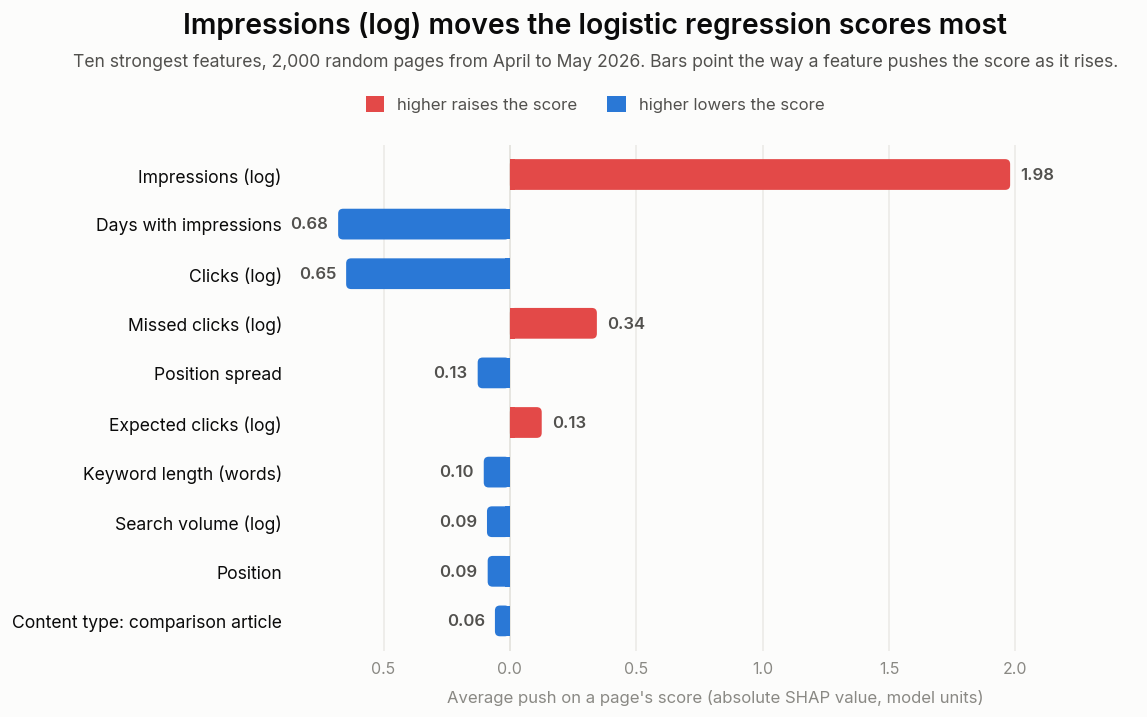

In [23]:
def load_inter() -> str:
    """Register the Inter font for this session and return the font family to draw with.

    The 400 and 600 weights are cached in the system temp folder, never in the project. If the
    download is unavailable, the chart falls back to matplotlib's default font, so the notebook still runs offline.
    """
    cache = os.path.join(tempfile.gettempdir(), "inter-font")
    os.makedirs(cache, exist_ok=True)
    try:
        for weight in (400, 600):
            path = os.path.join(cache, f"inter-{weight}.ttf")
            if not os.path.exists(path):
                urllib.request.urlretrieve(f"https://cdn.jsdelivr.net/fontsource/fonts/inter@latest/latin-{weight}-normal.ttf", path)
            font_manager.fontManager.addfont(path)
    except OSError:
        return "DejaVu Sans"
    return "Inter"


# Reference palette: diverging red (raises) and blue (lowers) with a grey midpoint; text in ink tokens, never series colours.
INK, SECONDARY, MUTED, GRID, ZERO, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#ecebe7", "#c9c8c3", "#fcfcfb"
RAISES, LOWERS, NEUTRAL = "#e34948", "#2a78d6", "#b4b2ac"
plt.rcParams.update({"font.family": load_inter()})

top10 = strength.head(10)[::-1]
side = {feature: 1 if direction[feature].startswith("higher raises") else -1 if direction[feature].startswith("higher lowers") else 0
        for feature in top10.index}
fig, ax = plt.subplots(figsize=(10, 6.2), dpi=120, facecolor=SURFACE)
fig.subplots_adjust(left=0.25, right=0.95, top=0.79, bottom=0.11)
ax.set_facecolor(SURFACE)
# Each side of zero is sized to its own longest bar (at least a third of the longest overall, so labels fit).
signed = pd.Series({feature: side[feature] * value for feature, value in top10.items()})
right_reach = max(signed.max(), top10.max() / 3, top10[signed == 0].max() / 2 if (signed == 0).any() else 0) * 1.25
left_reach = max(-signed.min(), top10.max() / 3, top10[signed == 0].max() / 2 if (signed == 0).any() else 0) * 1.25
ax.set_xlim(-left_reach, right_reach)
ax.set_ylim(-0.6, len(top10) - 0.4)

# Rounded data ends: a 5-pixel radius converted to data units on each axis, so corners stay circular.
box = ax.get_window_extent()
x_per_pixel, y_per_pixel = (left_reach + right_reach) / box.width, (len(top10) + 0.2) / box.height
radius, aspect, height = 5 * x_per_pixel, y_per_pixel / x_per_pixel, 0.62


def rounded_bar(left: float, right: float, row: int, colour: str, *, square_at_zero: bool) -> None:
    """Draw one bar with rounded ends; the end at the zero line stays square when the bar grows from it."""
    ax.add_patch(mpl.patches.FancyBboxPatch((left, row - height / 2), right - left, height, facecolor=colour, edgecolor="none",
                                            boxstyle=f"round,pad=0,rounding_size={radius}", mutation_aspect=aspect))
    if square_at_zero and right - left > 2 * radius:
        ax.add_patch(mpl.patches.Rectangle((0 if left == 0 else -radius, row - height / 2), radius, height, facecolor=colour, edgecolor="none"))


for row, (feature, value) in enumerate(top10.items()):
    if side[feature] == 0:
        rounded_bar(-value / 2, value / 2, row, NEUTRAL, square_at_zero=False)
        tip, align = value / 2, "left"
    else:
        tip = side[feature] * value
        rounded_bar(min(0, tip), max(0, tip), row, RAISES if side[feature] > 0 else LOWERS, square_at_zero=True)
        align = "left" if tip > 0 else "right"
    ax.annotate(f"{value:.2f}", (tip, row), xytext=(6 if align == "left" else -6, 0), textcoords="offset points",
                ha=align, va="center", color=SECONDARY, fontsize=10, fontweight="semibold")

ax.axvline(0, color=ZERO, linewidth=1.2, zorder=0)
ax.set_yticks(range(len(top10)), [label(feature) for feature in top10.index])
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{abs(value):.1f}"))
ax.set_xlabel("Average push on a page's score (absolute SHAP value, model units)", color=MUTED, fontsize=10, labelpad=8)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0, colors=MUTED, labelsize=9.5, pad=6)
ax.tick_params(axis="y", length=0, colors=INK, labelsize=10.5, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(0.5, 0.94, f"{label(strength.index[0])} moves the {EXPLAINED.lower()} scores most", ha="center", color=INK,
         fontsize=17, fontweight="semibold")
# Months written out in words: the Inter font has no arrow glyph.
first_month, second_month = (pd.Timestamp(f"{month}-01") for month in last_test.split(" → "))
fig.text(0.5, 0.895, f"Ten strongest features, 2,000 random pages from {first_month:%B} to {second_month:%B %Y}. "
         "Bars point the way a feature pushes the score as it rises.",
         ha="center", color=SECONDARY, fontsize=10.5)
key = [mpl.patches.Patch(facecolor=RAISES, label="higher raises the score"), mpl.patches.Patch(facecolor=LOWERS, label="higher lowers the score")]
if 0 in side.values():
    key.append(mpl.patches.Patch(facecolor=NEUTRAL, label="no single direction"))
fig.legend(handles=key, loc="upper center", bbox_to_anchor=(0.5, 0.865), ncol=len(key), frameon=False, fontsize=10,
           labelcolor=SECONDARY, handlelength=1.1, handleheight=1.1, columnspacing=1.8, borderaxespad=0)
plt.show()

**Finding:** impressions dominate, pushing a typical score about three times as hard as any other feature; more days with impressions and more clicks pull a page down, and more missed clicks push it up. Keyword research barely registers.


### 4e. The three cases, explained

**Method:** this cell shows each case's month-M numbers, what happened in May, both ranks, and the three features that pushed its score most, with their SHAP values.


In [24]:
def strongest_pushes(page: int, count: int = 3) -> str:
    """Return a page's largest SHAP pushes as readable text."""
    pushes = contributions.loc[page]
    return "; ".join(f"{label(feature)} {pushes[feature]:+.3f}" for feature in pushes.abs().sort_values(ascending=False).index[:count])


case_rows = []
for case, page in cases.items():
    if page is None:
        case_rows.append({"Case": case, "Model rank": "none found"})
        continue
    row = rows.loc[page]
    case_rows.append({"Case": case, "Model rank": f"{rank[page]:,.0f}",
                      "Rule B rank": f"{rank_b[page]:,.0f}" if scores[(last_test, BASELINE)][page] > 0 else "unranked (no shortfall in April)",
                      "April impressions": f"{row['impressions_m']:,.0f}", "April clicks": f"{row['clicks_m']:,.0f}",
                      "April expected clicks": f"{row['expected_bins_m']:,.1f}", "Position": f"{row['position_m']:.1f}",
                      "Position spread": f"{row['position_volatility_m']:.1f}",
                      "Search intent": row["main_intent"] if pd.notna(row["main_intent"]) else "unknown",
                      "May clicks ÷ expected": f"{row['clicks_next'] / row['expected_bins_next']:.2f}",
                      "Real shortfall in May": "yes" if row["target"] else "no",
                      "Strongest pushes (SHAP)": strongest_pushes(page)})
show_table(f"Three wrong cases, {EXPLAINED}, {last_test}", pd.DataFrame(case_rows).set_index("Case").fillna(""))

**Three wrong cases, Logistic regression, 2026-04 → 2026-05**

| Case | Model rank | Rule B rank | April impressions | April clicks | April expected clicks | Position | Position spread | Search intent | May clicks ÷ expected | Real shortfall in May | Strongest pushes (SHAP) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- | ---: | --- | --- |
| Model's highest-ranked miss | 5 | 1 | 144,986 | 12 | 842.4 | 2.2 | 0.3 | informational | 0.00 | no | Impressions (log) +6.327; Missed clicks (log) +3.699; Expected clicks (log) +1.503 |
| Large real shortfall the model ranked low | 9,054 | 4,877 | 2,896 | 3 | 11.5 | 11.1 | 5.0 | informational | 0.00 | yes | Impressions (log) +2.801; Missed clicks (log) +1.230; Days with impressions -0.625 |
| Rule B caught it, the model did not | 123 | 5 | 150,907 | 310 | 721.1 | 3.8 | 0.3 | transactional | 0.28 | yes | Impressions (log) +6.774; Missed clicks (log) +3.800; Clicks (log) -3.334 |

**Finding:** each wrong case shows a limit of the approach. **The highest-ranked miss** (model rank 5, rule B rank 1) had 144,986 impressions in April but only 12 clicks against 842.4 expected. It is the same page the baseline notebook found had fallen to 103 impressions in May: it lost its visibility, so May could not confirm a shortfall either way. Both scorers picked it, and no click-through model could have known. **The large real shortfall ranked low** (rank 9,054) is a small page (2,896 impressions, 3 clicks against 11.5 expected) with an unstable rank (spread 5.0): its April gap was too small to stand out, and it then dropped to no clicks in May. **The page rule B caught and the model did not** (rank 123 against 5) is a very large buying-intent page: 150,907 impressions and 310 clicks against 721.1 expected, about 411 clicks missed. Its impressions (+6.774) and missed clicks (+3.800) push it up, but its 310 clicks pull it back (−3.334), so it lands just outside the top 100. Rule B counts missed clicks in absolute terms and puts it fifth; this is the remaining Capture@50 gap in one page.


**Method:** this cell checks the honesty conditions in code one last time: the features hold no month M+1 or product field, every scorer was judged on the same pages, and no test client ever reached its model's training rows (both checked when the split was built).


In [25]:
for test in TESTS:
    index = pairs[test].index
    assert all(scores[(test, scorer)].index.equals(index) for scorer in SCORERS), f"{test}: scorers judged on different pages."
show("Leakage and fairness check (all passed)", {
    "features": f"{len(FEATURES)}, all from month M search data, rule B's month-M score, or keyword research",
    "month M+1 or product fields in the features": "none",
    "training targets after the test pair's month M": "none",
    "test clients in their model's training rows": "none",
    "scorers judged on the same pages": "yes, every page of each test pair",
    "settings chosen from test scores": "none (fixed before training)",
})

**Leakage and fairness check (all passed)**

| Measure | Value |
| --- | --- |
| features | 25, all from month M search data, rule B's month-M score, or keyword research |
| month M+1 or product fields in the features | none |
| training targets after the test pair's month M | none |
| test clients in their model's training rows | none |
| scorers judged on the same pages | yes, every page of each test pair |
| settings chosen from test scores | none (fixed before training) |

**Finding:** every check passes: the 25 features hold no month M+1 or product field, no training target falls after the test pair's month M, no test client reached its model's training rows, every scorer was judged on the same pages, and no setting was chosen from test scores.


## Limitations

- **Two test pairs, 50 pages each.** One page moves Precision@50 by 0.02, the same size as the comparison margin, so a narrow win or loss is within noise. A bootstrap interval on the gap would show how firm it is.
- **Untuned models.** The settings were fixed for honesty; gradient boosting in particular may gain from tuning inside the training data, so its result is a floor, not a ceiling.
- **The size gate remains.** The target can only be met by pages with enough traffic to rule out luck, so every scorer favours large pages; the size-band results are the fairer comparison.
- **The models inherit the target's view.** They predict the locked target, which judges clicks against a position-and-client expectation, so they share its blind spots, such as pages that lose visibility rather than click-through.
- **Two choices followed an earlier run.** After reading an earlier run, gradient boosting's stopping rule was made steadier and rule B's two month-M signals were added as features; logistic regression's mean Precision@50 rose from 0.870 to 0.890 and its Capture@50 from 2.33% to 3.59%. The comparison rule, the metrics, the split, and the settings were fixed before any run, but the test pairs had been seen, so these are development results; the sealed May→June pair, never read, is the clean test.
- **No page is seen directly.** The data is pseudonymized, so the wrong cases are read through their numbers, not their titles or results pages.


## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
